
------- ALL LIBRARIES LOADED SUCCESSFULLY --------
rasterio version: 1.5.1
geopandas version: 1.1.4
folium version: 0.20.0
google earth version: 1.7.40
Validated feature tensor shape: (224, 224, 8)


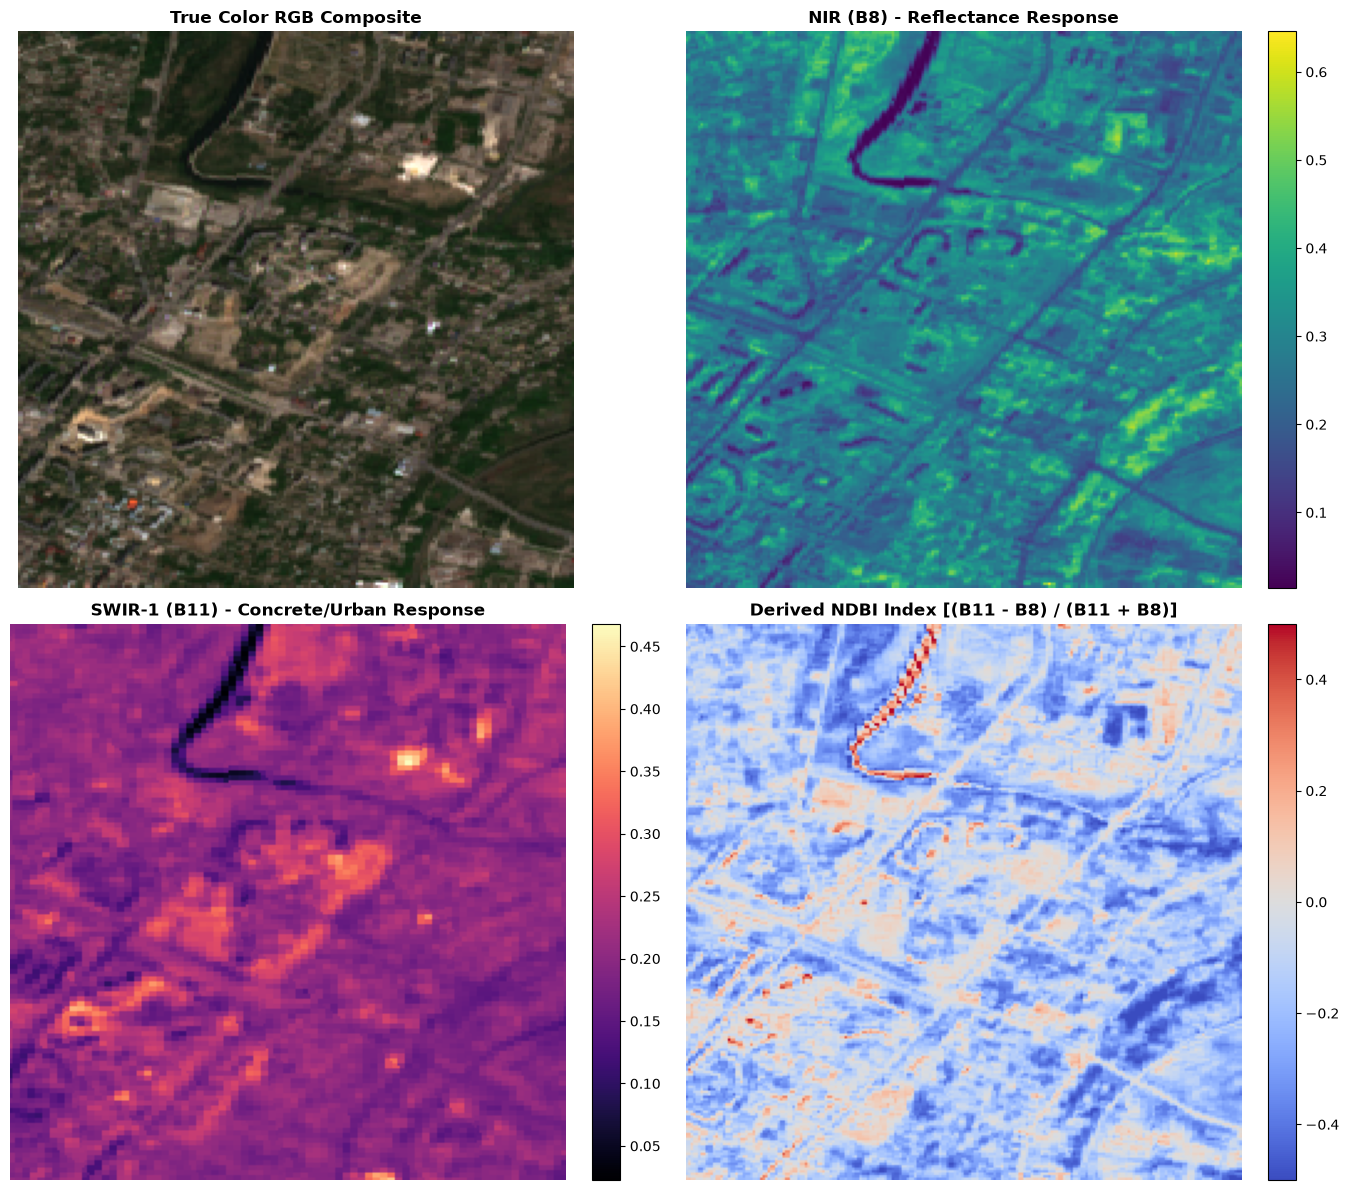

In [2]:
# 01. ENVIRONMENT SETUP & AUTHENTICATION
import ee
import folium
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import rasterio

print("\n------- ALL LIBRARIES LOADED SUCCESSFULLY --------")
print(f"rasterio version: {rasterio.__version__}")
print(f"geopandas version: {gpd.__version__}")
print(f"folium version: {folium.__version__}")
print(f"google earth version: {ee.__version__}")

try:
    ee.Initialize(project="ee-undergrad-thesis-509519")
except Exception:
    ee.Authenticate()
    ee.Initialize(project="ee-undergrad-thesis-509519")

# 02. DEFINE REGION OF INTEREST & PARAMETERS
# Mariupol area bounds roughly a 2km x 2km patch
WEST, SOUTH, EAST, NORTH = 37.55, 47.10, 37.57, 47.12
ROI = ee.Geometry.BBox(WEST, SOUTH, EAST, NORTH)

TARGET_BANDS = ['B2', 'B3', 'B4', 'B8', 'B11', 'B12']
band_idx = {name: idx for idx, name in enumerate(TARGET_BANDS)}

# 03. FETCH & PROCESS SENTINEL-2 IMAGE DATA
# Retrieve the least cloudy recent Sentinel-2 image over the Mariupol ROI
image = (
    ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
    .filterBounds(ROI)
    .filterDate('2024-01-01', '2024-06-01')
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10))
    .select(TARGET_BANDS)
    .sort('system:time_start', False)
    .first()
    .reproject(crs='EPSG:4326', scale=10)
)

# Extract spatial pixel data into a local NumPy array format
pixel_data = image.sampleRectangle(region=ROI, defaultValue=0)
band_arrays = [np.array(pixel_data.get(b).getInfo()) for b in TARGET_BANDS]
arr_3d = np.stack(band_arrays, axis=-1)

# Normalize surface reflectance values to the [0, 1] range (Sentinel-2 scale factor is 10,000)
arr_float = np.clip(arr_3d / 10000.0, 0, 1)

# Extract individual normalized spectral bands
b2_blue  = arr_float[:, :, band_idx['B2']]
b3_green = arr_float[:, :, band_idx['B3']]
b4_red   = arr_float[:, :, band_idx['B4']]
b8_nir   = arr_float[:, :, band_idx['B8']]
b11_swir = arr_float[:, :, band_idx['B11']]

# 04. CALCULATE SPECTRAL INDICES (NDVI & NDBI)
eps = 1e-10
# Normalized Difference Built-up Index (highlights concrete/urban infrastructure)
ndbi = np.clip((b11_swir - b8_nir) / (b11_swir + b8_nir + eps), -1.0, 1.0)
# Normalized Difference Vegetation Index (highlights vegetation health)
ndvi = np.clip((b8_nir - b4_red) / (b8_nir + b4_red + eps), -1.0, 1.0)

# Combine spectral bands and derived indices into a single feature tensor
feature_tensor = np.concatenate([
    arr_float,
    np.expand_dims(ndbi, axis=-1),
    np.expand_dims(ndvi, axis=-1)  # Appended along the final channel axis
], axis=-1)

print(f"Validated feature tensor shape: {feature_tensor.shape}")

# 05. VISUALIZE MULTI-BAND RESPONSES & INDICES
# Multiplier (2.5) applied to boost brightness for RGB visualization display scaling
rgb_composite = np.clip(np.dstack([b4_red, b3_green, b2_blue]) * 2.5, 0, 1)

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Top-Left: RGB Preview placeholder (or use axes[0,0] for RGB if desired)
axes[0, 0].imshow(rgb_composite)
axes[0, 0].set_title("True Color RGB Composite", fontsize=12, fontweight='bold')
axes[0, 0].axis('off')

# Top-Right: NIR Response
im1 = axes[0, 1].imshow(b8_nir, cmap='viridis')
axes[0, 1].set_title("NIR (B8) - Reflectance Response", fontsize=12, fontweight='bold')
axes[0, 1].axis('off')
plt.colorbar(im1, ax=axes[0, 1], fraction=0.046, pad=0.04)

# Bottom-Left: SWIR-1 Response (Urban/Concrete)
im2 = axes[1, 0].imshow(b11_swir, cmap='magma')
axes[1, 0].set_title("SWIR-1 (B11) - Concrete/Urban Response", fontsize=12, fontweight='bold')
axes[1, 0].axis('off')
plt.colorbar(im2, ax=axes[1, 0], fraction=0.046, pad=0.04)

# Bottom-Right: NDBI Heatmap
im3 = axes[1, 1].imshow(ndbi, cmap='coolwarm', vmin=-0.5, vmax=0.5)
axes[1, 1].set_title("Derived NDBI Index [(B11 - B8) / (B11 + B8)]", fontsize=12, fontweight='bold')
axes[1, 1].axis('off')
plt.colorbar(im3, ax=axes[1, 1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()